Evaluate machine learning models for bias and fairness, analyzing subgroup disparities and employing fairness metrics (e.g., demographic parity, equal opportunity) to ensure ethical and equitable model deployment.

In [36]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

In [37]:
np.random.seed(42)
n_samples = 1500

In [38]:
age_group = np.random.choice(['Younger', 'Senior'], size=n_samples, p=[0.60, 0.40])
gender = np.random.choice(['Female', 'Male'], size=n_samples, p=[0.52, 0.48])

In [39]:
white_cell_count = np.random.normal(8.5, 2.5, n_samples).clip(3, 20).round(1)
crp_level = np.random.exponential(scale=12, size=n_samples).round(1)
comorbidity_index = np.random.poisson(lam=1.8, size=n_samples).clip(0, 6)

In [40]:
logits = (
    -2.8
    + 0.12 * (white_cell_count - 8.5)
    + 0.04 * crp_level
    + 0.65 * comorbidity_index
    + 0.40 * (age_group == 'Senior').astype(int)
)

In [41]:
probs = 1 / (1 + np.exp(-logits))
y_true = (probs > np.random.uniform(0, 1, n_samples)).astype(int)

In [42]:
biased_logits = logits - 0.85 * (age_group == 'Senior').astype(int)
biased_probs = 1 / (1 + np.exp(-biased_logits))
y_pred = (biased_probs > 0.35).astype(int)

In [43]:
df_fairness = pd.DataFrame({
    'age_group': age_group,
    'gender': gender,
    'white_cell_count': white_cell_count,
    'crp_level': crp_level,
    'comorbidity_index': comorbidity_index,
    'y_true': y_true,
    'y_pred': y_pred,
    'pred_prob': biased_probs
})

In [44]:
def compute_fairness_metrics(df, sensitive_col, unprivileged_group='Senior', privileged_group='Younger'):
    metrics = []
    
    for group in [unprivileged_group, privileged_group]:
        sub = df[df[sensitive_col] == group]
        if len(sub) == 0:
            raise ValueError(f"Group '{group}' not found in column '{sensitive_col}'. Available values: {df[sensitive_col].unique()}")
            
        cm = confusion_matrix(sub['y_true'], sub['y_pred'], labels=[0, 1])
        TN, FP, FN, TP = cm.ravel()
        
        selection_rate = (TP + FP) / len(sub)
        tpr = TP / (TP + FN) if (TP + FN) > 0 else 0.0
        fpr = FP / (FP + TN) if (FP + TN) > 0 else 0.0
        accuracy = (TP + TN) / len(sub)
        
        metrics.append({
            'Subgroup': group,
            'Sample Size': len(sub),
            'Selection Rate (DP)': round(selection_rate, 4),
            'TPR / Recall (EO)': round(tpr, 4),
            'FPR (Alpha Risk)': round(fpr, 4),
            'Accuracy': round(accuracy, 4)
        })
        
    df_metrics = pd.DataFrame(metrics).set_index('Subgroup')
    
    dp_ratio = df_metrics.loc[unprivileged_group, 'Selection Rate (DP)'] / df_metrics.loc[privileged_group, 'Selection Rate (DP)']
    eo_diff = df_metrics.loc[unprivileged_group, 'TPR / Recall (EO)'] - df_metrics.loc[privileged_group, 'TPR / Recall (EO)']
    
    print(f"=== Subgroup Fairness Audit ({sensitive_col.upper()}) ===")
    print(df_metrics)
    print("\n--- Disparate Impact & Parity Summary ---")
    print(f"Demographic Parity Ratio (80% Rule) : {dp_ratio:.4f} {'[PASS]' if dp_ratio >= 0.8 else '[FAIL - Disparate Impact]'}")
    print(f"Equal Opportunity Difference (TPR Diff): {eo_diff:.4f} {'[PASS]' if abs(eo_diff) <= 0.05 else '[FAIL - Disparate Opportunity]'}")
    
    return df_metrics

In [45]:
df_age_metrics = compute_fairness_metrics(
    df_fairness, 
    sensitive_col='age_group', 
    unprivileged_group='Senior', 
    privileged_group='Younger'
)

=== Subgroup Fairness Audit (AGE_GROUP) ===
          Sample Size  Selection Rate (DP)  TPR / Recall (EO)  \
Subgroup                                                        
Senior            613               0.1550             0.2871   
Younger           887               0.2785             0.5598   

          FPR (Alpha Risk)  Accuracy  
Subgroup                              
Senior              0.0866    0.6998  
Younger             0.1776    0.7531  

--- Disparate Impact & Parity Summary ---
Demographic Parity Ratio (80% Rule) : 0.5566 [FAIL - Disparate Impact]
Equal Opportunity Difference (TPR Diff): -0.2727 [FAIL - Disparate Opportunity]


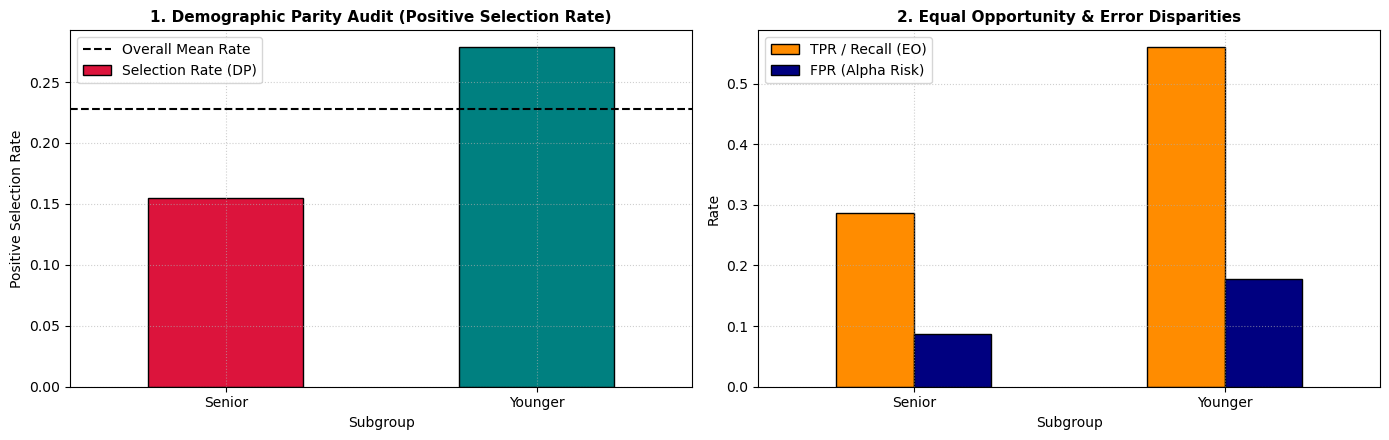

In [46]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

df_age_metrics['Selection Rate (DP)'].plot(
    kind='bar', ax=axes[0], color=['crimson', 'teal'], edgecolor='black'
)
axes[0].set_title("1. Demographic Parity Audit (Positive Selection Rate)", fontsize=11, fontweight='bold')
axes[0].set_ylabel("Positive Selection Rate")
axes[0].axhline(df_fairness['y_pred'].mean(), color='black', linestyle='--', label='Overall Mean Rate')
axes[0].grid(True, linestyle=':', alpha=0.6)
axes[0].legend()
axes[0].set_xticklabels(df_age_metrics.index, rotation=0)

df_age_metrics[['TPR / Recall (EO)', 'FPR (Alpha Risk)']].plot(
    kind='bar', ax=axes[1], color=['darkorange', 'navy'], edgecolor='black'
)
axes[1].set_title("2. Equal Opportunity & Error Disparities", fontsize=11, fontweight='bold')
axes[1].set_ylabel("Rate")
axes[1].grid(True, linestyle=':', alpha=0.6)
axes[1].set_xticklabels(df_age_metrics.index, rotation=0)

plt.tight_layout()
plt.show()